# Visualizing GridFM predictions on the case14 grid

This notebook presents the two topology-based plots of `gridfm_graphkit.utils.visualization`, on the IEEE 14-bus grid (`case14`):

- `visualize_quantity_heatmap`: ground truth, masked and reconstructed values of one quantity, drawn on the bus topology.
- `visualize_error`: nodal active-power residuals (power-balance error) in MW.

Both functions take a sample of the heterogeneous graph dataset, the model output and the data normalizer, and return a matplotlib `Figure`.

**No model is trained here.** We load one small `case14` scenario and simulate a model output as *ground truth + Gaussian noise*. The figures therefore illustrate the plots, not the quality of a real model. Everything runs on CPU in a few seconds.

## Installation

Create the environment from [`environment.yml`](../environment.yml) (Python 3.11, JupyterLab, CPU-only PyTorch), then select it as the notebook kernel:

```bash
conda env create -f environment.yml
conda activate gridfm-viz
```

(TO modify once PR#143 is merged) Until the `issue-42` branch is released, `gridfm-graphkit` is installed from it:

```bash
pip install "gridfm-graphkit @ git+https://github.com/CassNot/gridfm-graphkit.git@issue-42"
```

Once released, `pip install gridfm-graphkit` is enough. To work from a local clone, use `pip install -e path/to/gridfm-graphkit`.

In [11]:
import shutil
import subprocess
import tempfile
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from gridfm_graphkit.datasets.globals import (
    PD_H, PD_OUT, PG_H, PG_OUT, QD_H, QD_OUT, QG_H, QG_OUT, VA_H, VA_OUT, VM_H, VM_OUT,
)
from gridfm_graphkit.utils import visualization

warnings.filterwarnings("ignore", message="Sparse invariant checks")

print("torch", torch.__version__, "| gridfm-graphkit", version("gridfm-graphkit"))

torch 2.12.1+cpu | gridfm-graphkit 0.9.0.3


## Get a small `case14` dataset

The raw `case14_ieee` scenarios (about 250 kB) are part of the GridFM-GraphKit test data. A sparse, shallow clone downloads only that folder.

In [2]:
GRAPHKIT_REPO = "https://github.com/gridfm/gridfm-graphkit.git"
RAW_SUBDIR = "tests/data/case14_ieee/raw"
DATA_DIR = Path("data")
raw_dir = DATA_DIR / "case14_ieee" / "raw"

if not raw_dir.exists():
    with tempfile.TemporaryDirectory(ignore_cleanup_errors=True) as tmp:
        repo = Path(tmp) / "repo"
        subprocess.run(
            ["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", GRAPHKIT_REPO, str(repo)],
            check=True, capture_output=True,
        )
        subprocess.run(
            ["git", "-C", str(repo), "sparse-checkout", "set", RAW_SUBDIR],
            check=True, capture_output=True,
        )
        raw_dir.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(repo / RAW_SUBDIR, raw_dir)

print(sorted(path.name for path in raw_dir.iterdir()))

['branch_data.parquet', 'bus_data.parquet', 'gen_data.parquet', 'runtime_data.parquet', 'y_bus_data.parquet']


In [ ]:
# TEMPORARY: local alternative to the download cell above, for machines without GitHub access.
# Run this cell instead of the download cell. Remove it before publishing.
LOCAL_CASE14 = # Your local Path to gridfm-graphkit\tests\data\case14_ieee
DATA_DIR = Path("data")
raw_dir = DATA_DIR / "case14_ieee" / "raw"

if not raw_dir.exists():
    raw_dir.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(LOCAL_CASE14 / "raw", raw_dir)

print(sorted(path.name for path in raw_dir.iterdir()))

['branch_data.parquet', 'bus_data.parquet', 'gen_data.parquet', 'runtime_data.parquet', 'y_bus_data.parquet']


## The grid as a graph

GridFM represents a power grid as a graph: each **bus** is a node and each line or transformer an edge. The bus type says which quantities are imposed and which are unknown:

| Type | Shape in the plots | Known | To find out |
|------|--------------------|-------|-------------|
| `PQ` (load bus) | circle | active and reactive power | voltage magnitude and angle |
| `PV` (generator bus) | hexagon | active power and voltage magnitude | voltage angle, reactive power |
| `REF` (slack bus) | square | voltage magnitude and angle | generator power, which balances the grid |

In the power-flow task, the unknown quantities are *masked* in the input and the model must reconstruct them. The two plots below show the result on this topology, one bus per node.

## Load one sample

The GraphKit data module converts the raw tables into heterogeneous graphs, fits the normalizer and applies the power-flow masking. We take the first sample of the test split.

In [13]:
from gridfm_graphkit.datasets.hetero_powergrid_datamodule import LitGridHeteroDataModule
from gridfm_graphkit.io.param_handler import NestedNamespace

config = {
    "task": {"task_name": "PowerFlow"},
    "data": {
        "baseMVA": 100,
        "mask_value": 0.0,
        "mask_ref_vm": False,
        "normalization": "HeteroDataMVANormalizer",
        "networks": ["case14_ieee"],
        "scenarios": [72],
        "test_ratio": 0.1,
        "val_ratio": 0.1,
        "workers": 0,
        "split_by_load_scenario_idx": True,
        "stream_partitions": "auto",
    },
    "training": {"batch_size": 4},
    "seed": 0,
    "verbose": False,
}


class _Trainer:
    """Minimal stand-in for a Lightning Trainer: the data module only reads these attributes."""

    is_global_zero = True
    logger = None


dm = LitGridHeteroDataModule(NestedNamespace(**config), data_dir=str(DATA_DIR))
dm.trainer = _Trainer()
dm.setup("fit")

normalizer = dm.data_normalizers[0]
sample = dm.test_datasets[0][0]

print(f"baseMVA used for normalization: {normalizer.baseMVA:.1f} MW")
print("buses:", sample.x_dict["bus"].size(0), "| generators:", sample.x_dict["gen"].size(0))
print("buses with a masked Vm:", int(sample.mask_dict["bus"][:, VM_H].sum()))

Fitting normalizer on train set (58 scenarios)
baseMVA used for normalization: 82.2 MW
buses: 14 | generators: 4
buses with a masked Vm: 9


## Simulate a model output

A model returns a dictionary in normalized units: `"bus"` with the columns `VM, VA, PG, QG, PD, QD` and `"gen"` with the generator active power. We build it from the ground truth plus Gaussian noise (fixed seed).

`visualize_quantity_heatmap(..., "Pg")` reads the generator output, while `visualize_error` reads the bus-level `PG` column, so the simulation fills both consistently.

In [14]:
NOISE = {"vm": 0.01, "va": 0.01, "pg": 0.05, "qg": 0.02, "pd": 0.02, "qd": 0.02}


def simulate_output(sample, noise, seed=0):
    """Ground truth plus Gaussian noise, in the layout of a model output."""
    generator = torch.Generator().manual_seed(seed)

    def perturbed(values, sigma):
        return values + sigma * torch.randn(values.shape, generator=generator)

    y_bus, y_gen = sample.y_dict["bus"], sample.y_dict["gen"]
    gen_to_bus = sample.edge_index_dict[("gen", "connected_to", "bus")][1]
    gen_pg = perturbed(y_gen[:, PG_H], noise["pg"])

    bus = torch.zeros(y_bus.size(0), 6)
    bus[:, VM_OUT] = perturbed(y_bus[:, VM_H], noise["vm"])
    bus[:, VA_OUT] = perturbed(y_bus[:, VA_H], noise["va"])
    bus[:, QG_OUT] = perturbed(y_bus[:, QG_H], noise["qg"])
    bus[:, PD_OUT] = perturbed(y_bus[:, PD_H], noise["pd"])
    bus[:, QD_OUT] = perturbed(y_bus[:, QD_H], noise["qd"])
    bus[:, PG_OUT] = torch.zeros(y_bus.size(0)).index_add(0, gen_to_bus, gen_pg)
    return {"bus": bus, "gen": gen_pg.unsqueeze(1)}


output = simulate_output(sample, NOISE)
exact_output = simulate_output(sample, {name: 0.0 for name in NOISE})

## `visualize_quantity_heatmap`

This plot answers: *how close is the prediction to the truth, bus by bus?* It shows three panels with one shared color scale: the ground truth, the input with the masked buses in gray, and the reconstruction (known values kept, masked values taken from the output). Node shapes show the bus type: square for REF, hexagon for PV, circle for PQ.

c:\ProgramData\anaconda3\envs\gridfm-viz\Lib\site-packages\gridfm_graphkit\utils\visualization.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


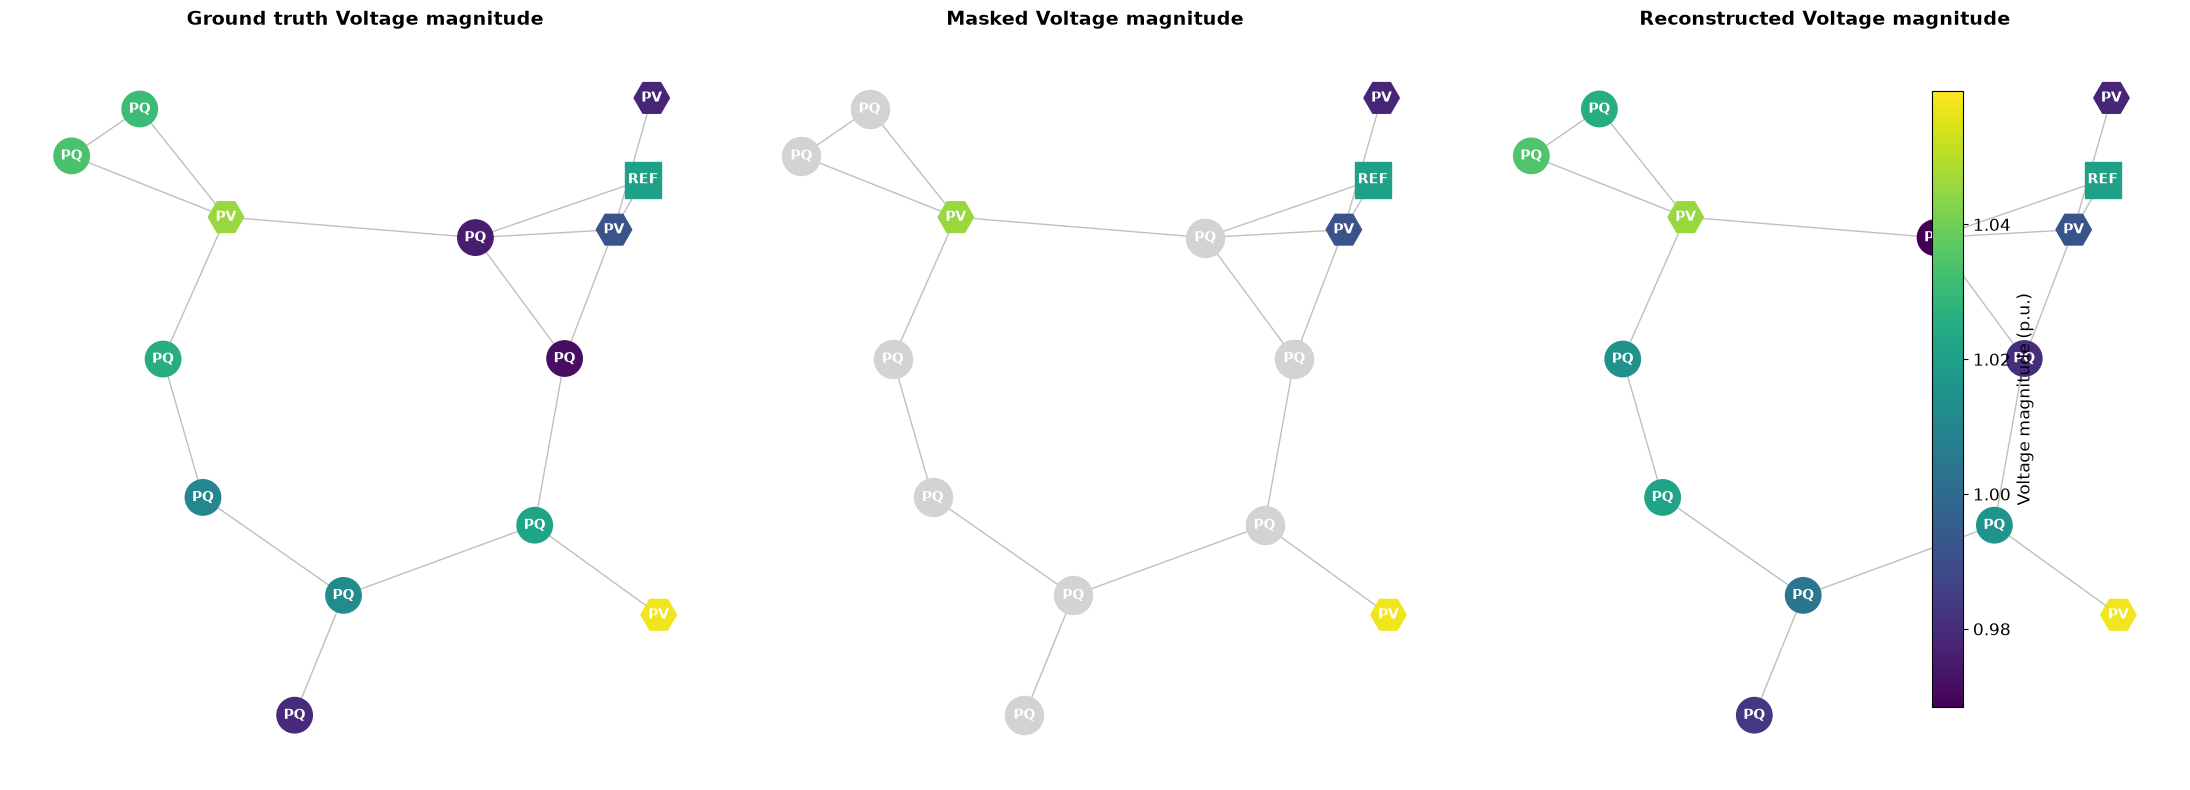

In [15]:
fig = visualization.visualize_quantity_heatmap(
    sample,
    output,
    quantity="Vm",
    quantity_name="Voltage magnitude",
    unit="p.u.",
    node_normalizer=normalizer,
)
plt.show()
plt.close(fig)

### How to read this figure

**What you see.** Each node is a bus and each edge a line or transformer (the layout is the same in the three panels). Node shape gives the bus type; color gives the voltage magnitude.

- **Left, ground truth:** the voltage of every bus in the scenario.
- **Middle, masked input:** what the model is asked to predict. Gray nodes have no voltage; these are the 9 `PQ` buses. The `PV` and `REF` buses keep their value because their voltage magnitude is a known set point.
- **Right, reconstruction:** the known values, completed at the gray nodes by the model output.

**How to analyze it.**

1. Compare the left and right panels, on the gray nodes only. The `PV` and `REF` nodes are copied from the truth, so they say nothing about the model.
2. Look at the pattern of the differences: a bias (all masked nodes systematically lighter or darker), a region (neighboring buses wrong together), or isolated nodes.
3. Keep the scale in mind: the three panels share one color bar, set by the smallest and largest value. Here it spans about 0.97 to 1.06 p.u., so an error of 0.01 p.u. changes the color only slightly. The eye is a first filter, not a measurement.
4. Check the physical range: voltage magnitudes are typically expected between 0.95 and 1.05 p.u.

The table below gives the numbers behind the right panel for the masked buses. With a noise of 0.01, the mean absolute error is expected to be close to 0.01 p.u.

In [16]:
import copy

from gridfm_graphkit.datasets.globals import PQ_H, PV_H

# Same unit conversion as the plotting function, applied to copies.
shown_sample, shown_output = copy.deepcopy(sample), copy.deepcopy(output)
normalizer.inverse_transform(shown_sample)
normalizer.inverse_output(shown_output, shown_sample)

masked = shown_sample.mask_dict["bus"][:, VM_H].bool()
true_vm = shown_sample.y_dict["bus"][:, VM_H]
predicted_vm = shown_output["bus"][:, VM_OUT]
bus_type = ["PQ" if row[PQ_H] == 1 else "PV" if row[PV_H] == 1 else "REF" for row in shown_sample.x_dict["bus"]]

print("bus  type  true Vm  reconstructed  error (p.u.)")
for bus in masked.nonzero().flatten().tolist():
    print(f"{bus:3d}  {bus_type[bus]:>4}  {true_vm[bus]:7.4f}  {predicted_vm[bus]:13.4f}  {predicted_vm[bus] - true_vm[bus]:+10.4f}")

error = (predicted_vm - true_vm)[masked]
print(f"\n{int(masked.sum())} masked buses | mean |error| = {error.abs().mean():.4f} p.u. | max |error| = {error.abs().max():.4f} p.u.")

bus  type  true Vm  reconstructed  error (p.u.)
  3    PQ   0.9718         0.9802     +0.0084
  4    PQ   0.9756         0.9684     -0.0072
  6    PQ   1.0217         1.0157     -0.0060
  8    PQ   1.0125         1.0039     -0.0086
  9    PQ   1.0103         1.0213     +0.0110
 10    PQ   1.0252         1.0145     -0.0107
 11    PQ   1.0335         1.0347     +0.0012
 12    PQ   1.0306         1.0249     -0.0057
 13    PQ   0.9794         0.9832     +0.0037

9 masked buses | mean |error| = 0.0069 p.u. | max |error| = 0.0110 p.u.


`quantity` accepts `"Pd"`, `"Qd"`, `"Qg"`, `"Vm"`, `"Va"` and `"Pg"` (generator power, aggregated per bus).

## `visualize_error`

This plot answers a different question: *is the prediction physically consistent?* At each bus, the power balance says that the active power injected (generation minus load) must equal the active power leaving through the lines, which is computed from the voltages and the grid admittances. The nodal residual is the absolute mismatch, in MW, computed with the same `PBELoss` as in training. A perfectly consistent prediction gives zero everywhere. It does not need the ground truth, only the model output.

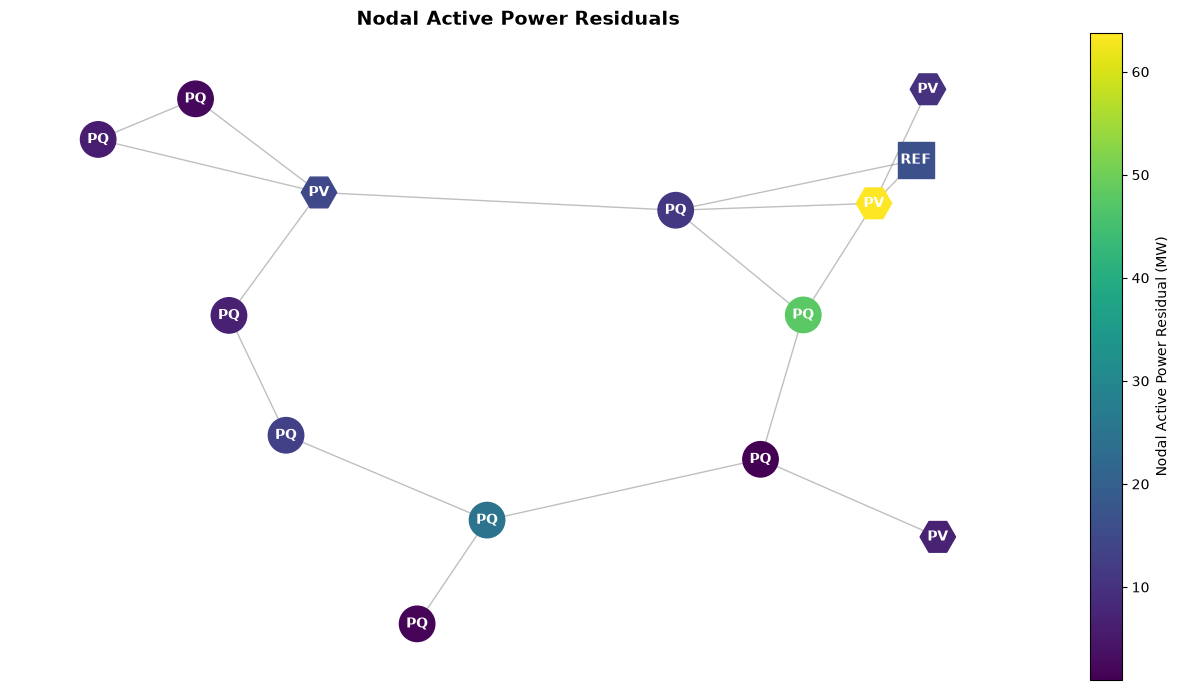

In [17]:
fig = visualization.visualize_error(sample, output, normalizer)
plt.show()
plt.close(fig)

### How to read this figure

Each node is a bus and its color is the absolute residual in MW: dark means balanced, bright means a violated power balance. The color bar is rescaled for each figure, so read the values on the bar rather than comparing colors between figures.

1. **Find the hot spots.** Most buses are close to balanced, while a few stand out. Here the brightest node is a `PV` bus, about 64 MW, next to the `REF` bus, with a `PQ` bus at about 50 MW right below it.
2. **Look at the neighbors.** A voltage error at one bus disturbs the flows on all its lines, so the residual spreads to adjacent buses. Hot spots often come as small clusters, as here.
3. **Do not expect a one-to-one match with the heatmap.** The residual is not the voltage error: it depends on voltage *differences* across lines and amplifies them (see the experiment below). A bus can have a small voltage error and a large residual.
4. **Remember what it does not tell you.** A small residual shows consistency, not accuracy. Use it together with the heatmap, and with the error against the ground truth when it is available.

In a real study, the residual is the plot to look at on samples where the model is wrong in a way that matters for operation: a prediction that breaks the power balance cannot be a feasible operating point.

As a sanity check, a noise-free output satisfies the power balance, so its residuals are numerically zero. The upper limit of the color bar is the largest residual:

In [18]:
fig = visualization.visualize_error(sample, exact_output, normalizer)
print(f"largest residual with a noise-free output: {fig.axes[1].get_ylim()[1]:.4f} MW")
plt.close(fig)

largest residual with a noise-free output: 0.0002 MW


### Which errors hurt the power balance?

The residual of a prediction answers a different question from the heatmap: not "is the value close to the truth?" but "is the prediction physically consistent?" Below, noise is applied to the voltages only, then to the active powers only, and the largest residual of each case is read from the color bar (the figures themselves are closed).

In [19]:
def largest_residual(noise):
    fig = visualization.visualize_error(sample, simulate_output(sample, noise), normalizer)
    value = fig.axes[1].get_ylim()[1]
    plt.close(fig)
    return value

no_noise = {name: 0.0 for name in NOISE}
scenarios = {
    "noise on voltages only (Vm, Va)": {**no_noise, "vm": NOISE["vm"], "va": NOISE["va"]},
    "noise on active powers only (Pg, Pd)": {**no_noise, "pg": NOISE["pg"], "pd": NOISE["pd"]},
    "noise on everything": NOISE,
}
for label, noise in scenarios.items():
    print(f"{label:<38} largest residual: {largest_residual(noise):7.2f} MW")

noise on voltages only (Vm, Va)        largest residual:   63.75 MW
noise on active powers only (Pg, Pd)   largest residual:    6.33 MW
noise on everything                    largest residual:   63.75 MW


**Takeaway.** The noise on the voltages (0.01 in normalized units) produces a far larger residual than the noise on the active powers (0.05 for `Pg`, 0.02 for `Pd`), although the latter is larger in normalized units. Line flows depend on voltage differences divided by small line impedances, so a small voltage error is amplified into a large power mismatch. This is why the power-balance residual is a demanding check, and why it can flag a prediction whose voltages look fine in the heatmap.

Change the values of `NOISE` and rerun the cells from *Simulate a model output* to explore other cases.

## Going further

- Replace `output` by the dictionary returned by a trained model on a normalized sample (`model(...)` on the same `sample`) to plot real predictions.
- Plot the generator active power aggregated per bus with `quantity="Pg"`, `unit="MW"`.
- Close figures with `plt.close(fig)` after displaying them when plotting many samples.